# Day 19 — SQL with Python for Data Science

**Fase 1 — Python Basics · Dia 19/28 · 18/11/2026**

Hoje eu aprendo a combinar **SQL** com Python: o módulo nativo `sqlite3`, a integração `pandas` ↔ SQL (`to_sql()` / `read_sql_query()`) e o **SQLAlchemy** como camada de conexão reutilizável em fluxos de Ciência de Dados.

### Objetivos de aprendizagem
- Entender **por que SQL é uma habilidade central** para cientistas de dados.
- Criar bancos SQLite em memória, tabelas e inserir dados com `sqlite3` (com *placeholders* seguros).
- Carregar datasets públicos do seaborn (`tips`, `titanic`, `penguins`, `flights`) no SQLite com `DataFrame.to_sql()`.
- Escrever consultas com `SELECT`, `WHERE`, `ORDER BY`, `LIMIT`, agregações (`GROUP BY`, `HAVING`) e `JOIN`s.
- Usar **subconsultas**, **CTEs** (`WITH`) e **funções de janela** (`ROW_NUMBER`, `RANK`, `LAG`, `LEAD`).
- Trazer resultados para DataFrames com `pd.read_sql_query()` e usar parâmetros.
- Usar o **SQLAlchemy 2.x** (Core + um mapeamento ORM simples) num fluxo de DS.
- Aplicar tudo a um **corpus em inglês (NLTK Brown Corpus)** pensando em ensino de inglês.
- Conhecer boas práticas: índices, `EXPLAIN QUERY PLAN` e quando usar SQL vs. pandas.

### Dados utilizados (apenas fontes públicas reais)
| Dataset | Fonte | Uso |
| --- | --- | --- |
| `tips`, `titanic`, `penguins`, `flights` | `seaborn.load_dataset` | consultas, agregações, JOINs, janelas |
| `iris` | `sklearn.datasets.load_iris` | SQLAlchemy Core/ORM |
| Brown Corpus | `nltk.corpus.brown` | exemplo aplicado de NLP/educação |

## 1. Por que SQL importa para cientistas de dados?

Antes de qualquer modelo, os dados precisam ser **encontrados, filtrados e agregados** — e na maioria das empresas eles vivem em bancos relacionais (PostgreSQL, MySQL, SQL Server, BigQuery, Snowflake...).

- Análises de vagas de Ciência de Dados costumam apontar que **cerca de 55–64% dos anúncios pedem SQL** (o percentual varia conforme a fonte, o país e o ano da coleta), o que coloca SQL entre as habilidades mais requisitadas, ao lado de Python.
- SQL é **declarativo**: eu digo *o que* quero, e o otimizador do banco decide *como* buscar.
- Empurrar filtros e agregações para o banco evita trazer milhões de linhas para a memória do Python.

**Fluxo típico em DS:** `banco SQL → consulta (filtro/agregação) → DataFrame pandas → EDA/modelagem`.

Neste notebook uso o **SQLite**, que já vem com o Python (`sqlite3`) e não precisa de servidor — ideal para aprender, prototipar e para projetos pequenos.

In [1]:
# Imports and environment check
import sqlite3
import time
from collections import Counter

import numpy as np
import pandas as pd
import seaborn as sns
import sqlalchemy
from sqlalchemy import (Float, MetaData, String, Table, create_engine,
                        func, select, text)
from sqlalchemy.orm import DeclarativeBase, Mapped, Session, mapped_column
from sklearn.datasets import load_iris

pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

print(f"Python sqlite3 module -> SQLite engine version: {sqlite3.sqlite_version}")
print(f"pandas {pd.__version__} | SQLAlchemy {sqlalchemy.__version__} | seaborn {sns.__version__}")

# Window functions require SQLite >= 3.25
major, minor, *_ = map(int, sqlite3.sqlite_version.split("."))
assert (major, minor) >= (3, 25), "Window functions need SQLite 3.25+"

Python sqlite3 module -> SQLite engine version: 3.40.1
pandas 2.3.3 | SQLAlchemy 2.1.9 | seaborn 0.13.2


## 2. `sqlite3` — o motor SQL embutido no Python

O fluxo básico do `sqlite3`:
1. `sqlite3.connect(...)` abre uma conexão (`":memory:"` cria um banco temporário na RAM).
2. `conn.cursor()` / `conn.execute()` envia comandos SQL.
3. `conn.commit()` confirma as alterações (transação).
4. `conn.close()` fecha a conexão.

⚠️ **Nunca** monte SQL com f-strings a partir de dados externos: use **placeholders** (`?` ou `:nome`) para evitar *SQL injection* e problemas de aspas.

Para ter dados reais desde o início, vou criar uma tabela manualmente e inserir **algumas linhas reais do dataset `tips`**.

In [2]:
# Create an in-memory database and a table by hand
conn_demo = sqlite3.connect(":memory:")
cur = conn_demo.cursor()

cur.execute('''
    CREATE TABLE tips_sample (
        id          INTEGER PRIMARY KEY AUTOINCREMENT,
        total_bill  REAL    NOT NULL,
        tip         REAL    NOT NULL,
        day         TEXT    NOT NULL,
        party_size  INTEGER CHECK (party_size > 0)
    )
''')

# Real rows taken from seaborn's tips dataset (first 5 records)
tips_raw = sns.load_dataset("tips")
rows = list(
    tips_raw.head(5)[["total_bill", "tip", "day", "size"]]
    .astype({"day": str})
    .itertuples(index=False, name=None)
)
print(rows)

# Parameterized insert with '?' placeholders (safe against SQL injection)
cur.executemany(
    "INSERT INTO tips_sample (total_bill, tip, day, party_size) VALUES (?, ?, ?, ?)",
    rows,
)
conn_demo.commit()
print("Rows inserted:", cur.rowcount)

[(16.99, 1.01, 'Sun', 2), (10.34, 1.66, 'Sun', 3), (21.01, 3.5, 'Sun', 3), (23.68, 3.31, 'Sun', 2), (24.59, 3.61, 'Sun', 4)]
Rows inserted: 5


In [3]:
# Reading results: fetchall returns a list of tuples
for row in conn_demo.execute("SELECT id, total_bill, tip, day FROM tips_sample"):
    print(row)

# sqlite3.Row gives dict-like access by column name
conn_demo.row_factory = sqlite3.Row
first = conn_demo.execute("SELECT * FROM tips_sample WHERE id = :id", {"id": 1}).fetchone()
print("\nNamed access ->", dict(first))

# Schema inspection through SQLite's catalog table
print(conn_demo.execute("SELECT sql FROM sqlite_master WHERE name = 'tips_sample'").fetchone()[0])

(1, 16.99, 1.01, 'Sun')
(2, 10.34, 1.66, 'Sun')
(3, 21.01, 3.5, 'Sun')
(4, 23.68, 3.31, 'Sun')
(5, 24.59, 3.61, 'Sun')

Named access -> {'id': 1, 'total_bill': 16.99, 'tip': 1.01, 'day': 'Sun', 'party_size': 2}
CREATE TABLE tips_sample (
        id          INTEGER PRIMARY KEY AUTOINCREMENT,
        total_bill  REAL    NOT NULL,
        tip         REAL    NOT NULL,
        day         TEXT    NOT NULL,
        party_size  INTEGER CHECK (party_size > 0)
    )


In [4]:
# Transactions: the connection works as a context manager that commits or rolls back
try:
    with conn_demo:  # opens a transaction
        conn_demo.execute(
            "INSERT INTO tips_sample (total_bill, tip, day, party_size) VALUES (?, ?, ?, ?)",
            (10.0, 1.0, "Sun", 0),  # violates CHECK (party_size > 0)
        )
except sqlite3.IntegrityError as exc:
    print("Rolled back ->", exc)

n = conn_demo.execute("SELECT COUNT(*) FROM tips_sample").fetchone()[0]
print("Rows after failed transaction:", n)  # still 5
conn_demo.close()

Rolled back -> CHECK constraint failed: party_size > 0
Rows after failed transaction: 5


## 3. Carregando datasets do seaborn no SQLite com `to_sql()`

Inserir linha a linha é didático, mas em DS o mais comum é **despejar um DataFrame inteiro** numa tabela com `DataFrame.to_sql()`:

- `if_exists="replace"` recria a tabela; `"append"` adiciona linhas.
- `index=False` evita gravar o índice do pandas como coluna.
- Colunas `category` do pandas viram `TEXT` — por isso converto para `str`/`object` antes.

Vou criar um banco `ds_day19` em memória com quatro tabelas reais: `tips`, `titanic`, `penguins` e `flights`.

In [5]:
def load_seaborn_tables(conn: sqlite3.Connection, names: list[str]) -> dict[str, pd.DataFrame]:
    '''Load seaborn datasets into SQLite tables with the same name.

    Categorical columns are cast to plain strings so SQLite stores them as TEXT.
    Returns the original DataFrames for later comparison with SQL results.
    '''
    frames = {}
    for name in names:
        df = sns.load_dataset(name)
        cat_cols = df.select_dtypes(include="category").columns
        df[cat_cols] = df[cat_cols].astype("object")
        df.to_sql(name, conn, if_exists="replace", index=False)
        frames[name] = df
        print(f"{name:<9} -> {len(df):>4} rows, {df.shape[1]} columns")
    return frames


conn = sqlite3.connect(":memory:")
frames = load_seaborn_tables(conn, ["tips", "titanic", "penguins", "flights"])

tips      ->  244 rows, 7 columns
titanic   ->  891 rows, 15 columns
penguins  ->  344 rows, 7 columns
flights   ->  144 rows, 3 columns


In [6]:
def sql(query: str, params=None, con=None) -> pd.DataFrame:
    '''Run a SQL query and return a DataFrame (thin wrapper over pd.read_sql_query).'''
    return pd.read_sql_query(query, con or conn, params=params)


# List tables and inspect one schema with PRAGMA
display(sql("SELECT name, type FROM sqlite_master WHERE type = 'table' ORDER BY name"))
display(sql("PRAGMA table_info(penguins)"))

,name,type
0,flights,table
1,penguins,table
2,tips,table
3,titanic,table


,cid,name,type,notnull,dflt_value,pk
0,0,species,TEXT,0,None,0
1,1,island,TEXT,0,None,0
2,2,bill_length_mm,REAL,0,None,0
3,3,bill_depth_mm,REAL,0,None,0
4,4,flipper_length_mm,REAL,0,None,0
5,5,body_mass_g,REAL,0,None,0
6,6,sex,TEXT,0,None,0


## 4. Consultas básicas: `SELECT`, `WHERE`, `ORDER BY`, `LIMIT`

A ordem **lógica** de execução de uma consulta é diferente da ordem em que escrevemos:

`FROM → WHERE → GROUP BY → HAVING → SELECT → ORDER BY → LIMIT`

Isso explica, por exemplo, por que não posso usar no `WHERE` um *alias* criado no `SELECT`.

In [7]:
# Projection + filter + sort + limit
sql('''
    SELECT total_bill, tip, ROUND(tip * 100.0 / total_bill, 1) AS tip_pct, day, time, size
    FROM tips
    WHERE time = 'Dinner' AND size >= 4
    ORDER BY tip_pct DESC
    LIMIT 5
''')

,total_bill,tip,tip_pct,day,time,size
0,23.17,6.50,28.1,Sun,Dinner,4
1,20.69,5.00,24.2,Sun,Dinner,5
2,18.29,3.76,20.6,Sat,Dinner,4
3,25.89,5.16,19.9,Sat,Dinner,4
4,39.42,7.58,19.2,Sat,Dinner,4


In [8]:
# IN, BETWEEN, LIKE and IS NULL
display(sql('''
    SELECT species, island, bill_length_mm, body_mass_g
    FROM penguins
    WHERE island IN ('Biscoe', 'Dream')
      AND body_mass_g BETWEEN 5500 AND 6500
    ORDER BY body_mass_g DESC
    LIMIT 5
'''))

# Missing values: NaN in pandas becomes NULL in SQLite
display(sql("SELECT COUNT(*) AS missing_sex FROM penguins WHERE sex IS NULL"))
print("pandas check:", frames["penguins"]["sex"].isna().sum())

# LIKE with a wildcard
display(sql("SELECT DISTINCT embark_town FROM titanic WHERE embark_town LIKE 'S%'"))

,species,island,bill_length_mm,body_mass_g
0,Gentoo,Biscoe,49.2,6300.0
1,Gentoo,Biscoe,59.6,6050.0
2,Gentoo,Biscoe,51.1,6000.0
3,Gentoo,Biscoe,48.8,6000.0
4,Gentoo,Biscoe,45.2,5950.0


,missing_sex
0,11


pandas check: 11


,embark_town
0,Southampton


In [9]:
# CASE WHEN: derived categorical columns inside SQL
sql('''
    SELECT who, age, fare,
           CASE
               WHEN age IS NULL THEN 'unknown'
               WHEN age < 18    THEN 'minor'
               WHEN age < 60    THEN 'adult'
               ELSE 'senior'
           END AS age_group
    FROM titanic
    ORDER BY fare DESC
    LIMIT 6
''')

,who,age,fare,age_group
0,woman,35.0,512.3292,adult
1,man,36.0,512.3292,adult
2,man,35.0,512.3292,adult
3,man,19.0,263.0000,adult
4,woman,23.0,263.0000,adult
5,woman,24.0,263.0000,adult


## 5. Agregações: `GROUP BY`, `COUNT`, `SUM`, `AVG`, `MIN`, `MAX`, `HAVING`

- `GROUP BY` colapsa as linhas em grupos; cada coluna no `SELECT` deve ser agrupadora ou agregada.
- `WHERE` filtra **linhas antes** da agregação; `HAVING` filtra **grupos depois** da agregação.
- `COUNT(*)` conta linhas; `COUNT(col)` ignora `NULL`s — diferença importante em dados com valores faltantes.

In [10]:
# Basic aggregation on tips
agg_sql = sql('''
    SELECT day,
           COUNT(*)                 AS n_bills,
           ROUND(SUM(total_bill),2) AS revenue,
           ROUND(AVG(tip), 2)       AS avg_tip,
           MIN(tip)                 AS min_tip,
           MAX(tip)                 AS max_tip
    FROM tips
    GROUP BY day
    ORDER BY revenue DESC
''')
display(agg_sql)

# Same result with pandas, to verify
agg_pd = (frames["tips"].groupby("day")
          .agg(n_bills=("tip", "size"), revenue=("total_bill", "sum"), avg_tip=("tip", "mean"))
          .round(2).sort_values("revenue", ascending=False))
assert np.allclose(agg_sql["revenue"].values, agg_pd["revenue"].values)
print("SQL and pandas aggregations match ✔")

,day,n_bills,revenue,avg_tip,min_tip,max_tip
0,Sat,87,1778.40,2.99,1.00,10.00
1,Sun,76,1627.16,3.26,1.01,6.50
2,Thur,62,1096.33,2.77,1.25,6.70
3,Fri,19,325.88,2.73,1.00,4.73


SQL and pandas aggregations match ✔


In [11]:
# COUNT(*) vs COUNT(col): NULL handling in the titanic data
sql('''
    SELECT class,
           COUNT(*)                         AS passengers,
           COUNT(age)                       AS with_age,
           COUNT(*) - COUNT(age)            AS missing_age,
           ROUND(AVG(survived) * 100, 1)    AS survival_rate_pct
    FROM titanic
    GROUP BY class
    ORDER BY class
''')

,class,passengers,with_age,missing_age,survival_rate_pct
0,First,216,186,30,63.0
1,Second,184,173,11,47.3
2,Third,491,355,136,24.2


In [12]:
# WHERE (rows) + GROUP BY + HAVING (groups)
sql('''
    SELECT species, island, sex,
           COUNT(*)                  AS n,
           ROUND(AVG(body_mass_g),0) AS avg_mass_g
    FROM penguins
    WHERE sex IS NOT NULL
    GROUP BY species, island, sex
    HAVING COUNT(*) >= 20
    ORDER BY avg_mass_g DESC
''')

,species,island,sex,n,avg_mass_g
0,Gentoo,Biscoe,Male,61,5485.0
1,Gentoo,Biscoe,Female,58,4680.0
2,Adelie,Biscoe,Male,22,4050.0
3,Adelie,Dream,Male,28,4046.0
4,Adelie,Torgersen,Male,23,4035.0
5,Chinstrap,Dream,Male,34,3939.0
6,Chinstrap,Dream,Female,34,3527.0
7,Adelie,Torgersen,Female,24,3396.0
8,Adelie,Biscoe,Female,22,3369.0
9,Adelie,Dream,Female,27,3344.0


## 6. JOINs: `INNER JOIN` e `LEFT JOIN`

Bancos relacionais são **normalizados**: a informação fica distribuída em várias tabelas ligadas por chaves. Para não inventar dados, vou **derivar tabelas-dimensão dos próprios datasets reais**:

- `decks`: um registro por *deck* observado no `titanic` (com estatísticas do próprio deck).
- `species_dim`: um registro por espécie de pinguim, com chave numérica `species_id`.

Diferença essencial:
- **INNER JOIN** mantém só as linhas com correspondência nas duas tabelas.
- **LEFT JOIN** mantém todas as linhas da tabela da esquerda; sem correspondência → `NULL`.

In [13]:
# Build dimension tables FROM the real data using CREATE TABLE ... AS SELECT
conn.executescript('''
    DROP TABLE IF EXISTS decks;
    CREATE TABLE decks AS
    SELECT deck,
           COUNT(*)              AS deck_passengers,
           ROUND(AVG(fare), 2)   AS deck_avg_fare
    FROM titanic
    WHERE deck IS NOT NULL
    GROUP BY deck;

    DROP TABLE IF EXISTS species_dim;
    CREATE TABLE species_dim AS
    SELECT ROW_NUMBER() OVER (ORDER BY species) AS species_id,
           species,
           COUNT(DISTINCT island)              AS n_islands
    FROM penguins
    GROUP BY species;
''')
display(sql("SELECT * FROM decks ORDER BY deck"))
display(sql("SELECT * FROM species_dim"))

,deck,deck_passengers,deck_avg_fare
0,A,15,39.62
1,B,47,113.51
2,C,59,100.15
3,D,33,57.24
4,E,32,46.03
5,F,13,18.70
6,G,4,13.58


,species_id,species,n_islands
0,1,Adelie,3
1,2,Chinstrap,1
2,3,Gentoo,1


In [14]:
# INNER JOIN vs LEFT JOIN row counts (most titanic passengers have no recorded deck)
counts = sql('''
    SELECT
        (SELECT COUNT(*) FROM titanic t INNER JOIN decks d ON t.deck = d.deck) AS inner_rows,
        (SELECT COUNT(*) FROM titanic t LEFT  JOIN decks d ON t.deck = d.deck) AS left_rows,
        (SELECT COUNT(*) FROM titanic)                                          AS titanic_rows
''')
display(counts)

# LEFT JOIN keeps passengers without a deck (deck columns become NULL)
sql('''
    SELECT t.class, t.fare, t.deck, d.deck_passengers, d.deck_avg_fare,
           ROUND(t.fare - d.deck_avg_fare, 2) AS fare_vs_deck_avg
    FROM titanic AS t
    LEFT JOIN decks AS d ON t.deck = d.deck
    LIMIT 8
''')

,inner_rows,left_rows,titanic_rows
0,203,891,891


,class,fare,deck,deck_passengers,deck_avg_fare,fare_vs_deck_avg
0,Third,7.2500,None,NaN,NaN,NaN
1,First,71.2833,C,59.0,100.15,-28.87
2,Third,7.9250,None,NaN,NaN,NaN
3,First,53.1000,C,59.0,100.15,-47.05
4,Third,8.0500,None,NaN,NaN,NaN
5,Third,8.4583,None,NaN,NaN,NaN
6,First,51.8625,E,32.0,46.03,5.83
7,Third,21.0750,None,NaN,NaN,NaN


In [15]:
# INNER JOIN with an aggregated subquery: compare each penguin with its species/sex mean
sql('''
    SELECT s.species_id, p.species, p.sex, p.body_mass_g,
           g.avg_mass,
           ROUND(p.body_mass_g - g.avg_mass, 1) AS diff_from_group
    FROM penguins AS p
    INNER JOIN species_dim AS s ON p.species = s.species
    INNER JOIN (
        SELECT species, sex, AVG(body_mass_g) AS avg_mass
        FROM penguins
        WHERE sex IS NOT NULL
        GROUP BY species, sex
    ) AS g ON p.species = g.species AND p.sex = g.sex
    ORDER BY diff_from_group DESC
    LIMIT 5
''')

,species_id,species,sex,body_mass_g,avg_mass,diff_from_group
0,2,Chinstrap,Male,4800.0,3938.970588,861.0
1,3,Gentoo,Male,6300.0,5484.836066,815.2
2,1,Adelie,Male,4775.0,4043.493151,731.5
3,1,Adelie,Male,4725.0,4043.493151,681.5
4,1,Adelie,Male,4700.0,4043.493151,656.5


## 7. Subconsultas e CTEs (`WITH`)

- **Subconsulta**: uma consulta dentro de outra (no `WHERE`, no `FROM` ou no `SELECT`).
- **CTE (Common Table Expression)**: um "passo nomeado" declarado com `WITH nome AS (...)`. Deixa a consulta legível como um *pipeline*, parecido com encadear etapas no pandas.

Regra prática: se a subconsulta tem mais de 3–4 linhas ou é reutilizada, transforme em CTE.

In [16]:
# Scalar subquery in WHERE: bills above the overall average
display(sql('''
    SELECT day, time, total_bill, tip
    FROM tips
    WHERE total_bill > (SELECT AVG(total_bill) FROM tips)
    ORDER BY total_bill DESC
    LIMIT 5
'''))

# IN with a subquery: passengers who embarked in towns with survival rate above 50%
sql('''
    SELECT embark_town, COUNT(*) AS n
    FROM titanic
    WHERE embark_town IN (
        SELECT embark_town FROM titanic
        GROUP BY embark_town HAVING AVG(survived) > 0.5
    )
    GROUP BY embark_town
''')

,day,time,total_bill,tip
0,Sat,Dinner,50.81,10.00
1,Sat,Dinner,48.33,9.00
2,Sat,Dinner,48.27,6.73
3,Sun,Dinner,48.17,5.00
4,Sun,Dinner,45.35,3.50


,embark_town,n
0,Cherbourg,168


In [17]:
# Multi-step CTE pipeline: survival by class and sex, compared with class average
sql('''
    WITH by_group AS (
        SELECT class, sex, COUNT(*) AS n, AVG(survived) AS surv
        FROM titanic
        GROUP BY class, sex
    ),
    by_class AS (
        SELECT class, AVG(survived) AS class_surv
        FROM titanic
        GROUP BY class
    )
    SELECT g.class, g.sex, g.n,
           ROUND(g.surv * 100, 1)                  AS survival_pct,
           ROUND(c.class_surv * 100, 1)            AS class_survival_pct,
           ROUND((g.surv - c.class_surv) * 100, 1) AS gap_pp
    FROM by_group AS g
    JOIN by_class AS c USING (class)
    ORDER BY g.class, g.sex
''')

,class,sex,n,survival_pct,class_survival_pct,gap_pp
0,First,female,94,96.8,63.0,33.8
1,First,male,122,36.9,63.0,-26.1
2,Second,female,76,92.1,47.3,44.8
3,Second,male,108,15.7,47.3,-31.5
4,Third,female,144,50.0,24.2,25.8
5,Third,male,347,13.5,24.2,-10.7


## 8. Funções de janela: `ROW_NUMBER`, `RANK`, `LAG`, `LEAD`

Funções de janela calculam valores **sobre um conjunto de linhas relacionadas sem colapsá-las** (diferente do `GROUP BY`). Sintaxe:

```sql
FUNCAO() OVER (PARTITION BY grupo ORDER BY coluna)
```

- `ROW_NUMBER()` numera 1, 2, 3... (sem empates).
- `RANK()` dá a mesma posição a empates e "pula" números (1, 1, 3).
- `LAG(col, k)` / `LEAD(col, k)` acessam a linha anterior/seguinte — perfeitos para séries temporais.
- Agregações com `OVER` (`SUM() OVER`, `AVG() OVER`) geram totais acumulados e médias móveis.

O SQLite suporta funções de janela desde a versão **3.25**.

In [18]:
# Top-2 bills per day: ROW_NUMBER inside a CTE, then filter
sql('''
    WITH ranked AS (
        SELECT day, total_bill, tip, size,
               ROW_NUMBER() OVER (PARTITION BY day ORDER BY total_bill DESC) AS rn,
               RANK()       OVER (PARTITION BY day ORDER BY size DESC)       AS size_rank
        FROM tips
    )
    SELECT * FROM ranked
    WHERE rn <= 2
    ORDER BY day, rn
''')

,day,total_bill,tip,size,rn,size_rank
0,Fri,40.17,4.73,4,1,1
1,Fri,28.97,3.00,2,2,3
2,Sat,50.81,10.00,3,1,15
3,Sat,48.33,9.00,4,2,2
4,Sun,48.17,5.00,6,1,1
5,Sun,45.35,3.50,3,2,23
6,Thur,43.11,5.00,4,1,5
7,Thur,41.19,5.00,5,2,4


In [19]:
# LAG / LEAD on the real monthly airline passengers series (flights, 1949-1960)
month_order = "CASE month " + " ".join(
    f"WHEN '{m}' THEN {i}" for i, m in enumerate(
        ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"], 1)
) + " END"

flights_win = sql(f'''
    WITH ordered AS (
        SELECT year, month, {month_order} AS month_num, passengers
        FROM flights
    )
    SELECT year, month, passengers,
           LAG(passengers, 1)  OVER w                        AS prev_month,
           LEAD(passengers, 1) OVER w                        AS next_month,
           passengers - LAG(passengers, 12) OVER w           AS yoy_change,
           ROUND(AVG(passengers) OVER (ORDER BY year, month_num
                 ROWS BETWEEN 2 PRECEDING AND CURRENT ROW), 1) AS moving_avg_3m
    FROM ordered
    WINDOW w AS (ORDER BY year, month_num)
    ORDER BY year, month_num
''')
flights_win.iloc[10:16]

,year,month,passengers,prev_month,next_month,yoy_change,moving_avg_3m
10,1949,Nov,104,119.0,118.0,NaN,119.7
11,1949,Dec,118,104.0,115.0,NaN,113.7
12,1950,Jan,115,118.0,126.0,3.0,112.3
13,1950,Feb,126,115.0,141.0,8.0,119.7
14,1950,Mar,141,126.0,135.0,9.0,127.3
15,1950,Apr,135,141.0,125.0,6.0,134.0


In [20]:
# Validate LAG(12) against pandas shift(12)
f = frames["flights"].copy()
pd_yoy = f["passengers"] - f["passengers"].shift(12)
assert np.allclose(pd_yoy.fillna(-1).values, flights_win["yoy_change"].fillna(-1).values)
print("SQL LAG(12) == pandas shift(12) ✔")

# Running total per year with SUM() OVER (PARTITION BY ...)
sql(f'''
    SELECT year, month, passengers,
           SUM(passengers) OVER (PARTITION BY year ORDER BY {month_order}) AS ytd_passengers
    FROM flights
    WHERE year = 1960
''').tail(4)

SQL LAG(12) == pandas shift(12) ✔


,year,month,passengers,ytd_passengers
8,1960,Sep,508,4431
9,1960,Oct,461,4892
10,1960,Nov,390,5282
11,1960,Dec,432,5714


## 9. `pd.read_sql_query()` — do SQL de volta para o DataFrame

O `read_sql_query()` é a ponte entre SQL e pandas. Recursos úteis:
- `params=`: passa valores com segurança (placeholders `?` ou `:nome` no SQLite).
- `parse_dates=`: converte colunas para datetime.
- `dtype=`: força tipos na leitura.
- `chunksize=`: devolve um **iterador** de DataFrames — útil para tabelas maiores que a memória.

In [21]:
# Named parameters (never build SQL with f-strings from user input!)
params = {"min_size": 3, "smoker": "Yes"}
df_params = pd.read_sql_query(
    "SELECT * FROM tips WHERE size >= :min_size AND smoker = :smoker",
    conn, params=params,
)
print(df_params.shape)

# Example of what NOT to do — an "injection" string is treated as a literal value with params
malicious = "Yes' OR '1'='1"
safe = pd.read_sql_query("SELECT COUNT(*) AS n FROM tips WHERE smoker = ?", conn, params=(malicious,))
print("Rows matched with a malicious string via params:", safe.loc[0, "n"])  # 0

# dtype control on read
df_typed = pd.read_sql_query("SELECT day, time, tip FROM tips", conn,
                             dtype={"day": "category", "time": "category"})
print(df_typed.dtypes)

(25, 7)
Rows matched with a malicious string via params: 0
day     category
time    category
tip      float64
dtype: object


In [22]:
# chunksize: stream a query in pieces and aggregate incrementally
total_fare, total_rows = 0.0, 0
for i, chunk in enumerate(pd.read_sql_query("SELECT fare FROM titanic", conn, chunksize=250)):
    total_fare += chunk["fare"].sum()
    total_rows += len(chunk)
    print(f"chunk {i}: {len(chunk)} rows")

print(f"Streaming mean fare = {total_fare / total_rows:.4f}")
print(f"pandas mean fare    = {frames['titanic']['fare'].mean():.4f}")

chunk 0: 250 rows
chunk 1: 250 rows
chunk 2: 250 rows
chunk 3: 141 rows
Streaming mean fare = 32.2042
pandas mean fare    = 32.2042


## 10. SQLAlchemy — uma camada reutilizável para fluxos de DS

O **SQLAlchemy** abstrai o banco: o mesmo código funciona com SQLite, PostgreSQL, MySQL etc. — só muda a *URL de conexão*. Ele tem duas camadas:

1. **Core**: `Engine`, `text()`, `Table`/`MetaData` e o construtor `select()` — SQL composto em Python.
2. **ORM**: classes Python mapeadas para tabelas.

Para DS, a abordagem "ORM-lite" costuma bastar: **`create_engine` + `text()`/`select()` + pandas**, usando o ORM apenas quando há regras de domínio a modelar. Vou usar o dataset **iris** do scikit-learn.

In [23]:
# Engine + pandas: the most common DS pattern
engine = create_engine("sqlite:///:memory:", echo=False)

iris_bunch = load_iris(as_frame=True)
iris = iris_bunch.frame.rename(columns=lambda c: c.replace(" (cm)", "").replace(" ", "_"))
iris["species"] = iris["target"].map(dict(enumerate(iris_bunch.target_names)))
iris = iris.drop(columns="target")

iris.to_sql("iris", engine, index=False, if_exists="replace")

# text() with bound parameters, executed inside a managed connection
with engine.connect() as cx:
    result = cx.execute(
        text("SELECT species, COUNT(*) AS n, ROUND(AVG(petal_length), 3) AS avg_petal "
             "FROM iris WHERE sepal_length > :min_len GROUP BY species"),
        {"min_len": 5.0},
    )
    for row in result:
        print(row._asdict())

pd.read_sql_query(text("SELECT * FROM iris LIMIT 3"), engine)

{'species': 'setosa', 'n': 22, 'avg_petal': 1.509}
{'species': 'versicolor', 'n': 47, 'avg_petal': 4.317}
{'species': 'virginica', 'n': 49, 'avg_petal': 5.573}


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa


In [24]:
# SQLAlchemy Core: describe the table once, then compose queries in Python
metadata = MetaData()
iris_tbl = Table("iris", metadata, autoload_with=engine)  # reflect existing schema
print([c.name for c in iris_tbl.columns])

stmt = (
    select(
        iris_tbl.c.species,
        func.count().label("n"),
        func.round(func.avg(iris_tbl.c.petal_width), 3).label("avg_petal_width"),
        func.max(iris_tbl.c.sepal_length).label("max_sepal_length"),
    )
    .where(iris_tbl.c.petal_length > 1.5)
    .group_by(iris_tbl.c.species)
    .order_by(func.avg(iris_tbl.c.petal_width).desc())
)
print(stmt)  # the generated SQL
pd.read_sql_query(stmt, engine)

['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']
SELECT iris.species, count(*) AS n, round(avg(iris.petal_width), :round_1) AS avg_petal_width, max(iris.sepal_length) AS max_sepal_length 
FROM iris 
WHERE iris.petal_length > :petal_length_1 GROUP BY iris.species ORDER BY avg(iris.petal_width) DESC


,species,n,avg_petal_width,max_sepal_length
0,virginica,50,2.026,7.9
1,versicolor,50,1.326,7.0
2,setosa,13,0.308,5.7


In [25]:
# A minimal ORM mapping: store model-experiment results (real metrics computed on iris)
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier


class Base(DeclarativeBase):
    pass


class Experiment(Base):
    '''One row per model evaluated with 5-fold cross-validation.'''
    __tablename__ = "experiments"
    id: Mapped[int] = mapped_column(primary_key=True)
    model: Mapped[str] = mapped_column(String(50))
    dataset: Mapped[str] = mapped_column(String(30))
    cv_mean: Mapped[float] = mapped_column(Float)
    cv_std: Mapped[float] = mapped_column(Float)


Base.metadata.create_all(engine)

X, y = iris_bunch.data, iris_bunch.target
models = {
    "LogisticRegression": LogisticRegression(max_iter=1000),
    "KNeighbors(k=5)": KNeighborsClassifier(),
    "DecisionTree(depth=3)": DecisionTreeClassifier(max_depth=3, random_state=42),
}
with Session(engine) as session:
    for name, model in models.items():
        scores = cross_val_score(model, X, y, cv=5)
        session.add(Experiment(model=name, dataset="iris",
                               cv_mean=float(scores.mean()), cv_std=float(scores.std())))
    session.commit()

    best = session.scalars(select(Experiment).order_by(Experiment.cv_mean.desc())).first()
    print(f"Best model: {best.model} ({best.cv_mean:.3f} ± {best.cv_std:.3f})")

pd.read_sql_query(select(Experiment), engine)

Best model: LogisticRegression (0.973 ± 0.025)


,id,model,dataset,cv_mean,cv_std
0,1,LogisticRegression,iris,0.973333,0.024944
1,2,KNeighbors(k=5),iris,0.973333,0.024944
2,3,DecisionTree(depth=3),iris,0.973333,0.024944


## 11. Aplicação: corpus de inglês para ensino (NLTK Brown Corpus) no SQLite

Agora uno SQL com meu interesse em **NLP aplicado ao ensino de inglês**. O **Brown Corpus** (1961) é um corpus público de inglês americano escrito, com ~1 milhão de palavras divididas em 15 gêneros (*news*, *fiction*, *learned*...).

Vou montar um pequeno **banco relacional de corpus**:

| Tabela | Conteúdo |
| --- | --- |
| `documents` | um registro por texto: `doc_id`, `genre`, `n_tokens`, `n_types` |
| `word_counts` | frequência de cada palavra em cada documento (`doc_id`, `word`, `freq`) |
| `lexicon` | ranking de frequência de cada palavra no corpus inteiro + **faixa de frequência** |

Pergunta pedagógica: **se um aluno conhece as 1.000 / 3.000 palavras mais frequentes, que porcentagem dos tokens de cada gênero ele cobre?** (Cobertura lexical é um indicador clássico de dificuldade de leitura.)

⚠️ As faixas `top_1000`, `1001_3000` etc. são **heurísticas baseadas em frequência no próprio Brown**, não níveis oficiais do CEFR.

In [26]:
import nltk

for pkg in ["brown"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import brown

GENRES = ["news", "editorial", "government", "learned", "fiction", "romance", "adventure", "humor"]

doc_rows, wc_rows = [], []
for genre in GENRES:
    for fid in brown.fileids(categories=genre):
        tokens = [w.lower() for w in brown.words(fid) if w.isalpha()]
        counts = Counter(tokens)
        doc_rows.append((fid, genre, len(tokens), len(counts)))
        wc_rows.extend((fid, w, c) for w, c in counts.items())

documents = pd.DataFrame(doc_rows, columns=["doc_id", "genre", "n_tokens", "n_types"])
word_counts = pd.DataFrame(wc_rows, columns=["doc_id", "word", "freq"])
print(documents.shape, word_counts.shape)
documents.head()

(277, 4) (192383, 3)


,doc_id,genre,n_tokens,n_types
0,ca01,news,1902,726
1,ca02,news,1894,776
2,ca03,news,1902,670
3,ca04,news,1986,812
4,ca05,news,1965,678


In [27]:
# Store the corpus in a dedicated SQLite database via SQLAlchemy
corpus_engine = create_engine("sqlite:///:memory:")
documents.to_sql("documents", corpus_engine, index=False)
word_counts.to_sql("word_counts", corpus_engine, index=False, chunksize=50_000)

# Build the lexicon table in SQL: global frequency, rank (window function) and a frequency band
with corpus_engine.begin() as cx:
    cx.execute(text('''
        CREATE TABLE lexicon AS
        WITH totals AS (
            SELECT word, SUM(freq) AS corpus_freq, COUNT(DISTINCT doc_id) AS n_docs
            FROM word_counts
            GROUP BY word
        )
        SELECT word, corpus_freq, n_docs,
               ROW_NUMBER() OVER (ORDER BY corpus_freq DESC, word) AS freq_rank,
               CASE
                   WHEN ROW_NUMBER() OVER (ORDER BY corpus_freq DESC, word) <= 1000 THEN 'top_1000'
                   WHEN ROW_NUMBER() OVER (ORDER BY corpus_freq DESC, word) <= 3000 THEN '1001_3000'
                   WHEN ROW_NUMBER() OVER (ORDER BY corpus_freq DESC, word) <= 9000 THEN '3001_9000'
                   ELSE 'beyond_9000'
               END AS freq_band
        FROM totals
    '''))

corpus_sql = lambda q, **kw: pd.read_sql_query(text(q), corpus_engine, params=kw or None)
display(corpus_sql("SELECT * FROM lexicon ORDER BY freq_rank LIMIT 8"))
display(corpus_sql("SELECT freq_band, COUNT(*) AS n_words FROM lexicon GROUP BY freq_band ORDER BY MIN(freq_rank)"))

,word,corpus_freq,n_docs,freq_rank,freq_band
0,the,39092,277,1,top_1000
1,of,19835,277,2,top_1000
2,and,15683,277,3,top_1000
3,to,14347,277,4,top_1000
4,a,12404,277,5,top_1000
5,in,11828,277,6,top_1000
6,was,5650,259,7,top_1000
7,that,5607,277,8,top_1000


,freq_band,n_words
0,top_1000,1000
1,1001_3000,2000
2,3001_9000,6000
3,beyond_9000,20469


In [28]:
# Lexical profile per genre: size, type-token ratio (mean per document, comparable lengths)
corpus_sql('''
    SELECT genre,
           COUNT(*)                                    AS n_docs,
           SUM(n_tokens)                               AS tokens,
           ROUND(AVG(n_tokens), 0)                     AS avg_tokens_per_doc,
           ROUND(AVG(n_types * 1.0 / n_tokens), 3)     AS mean_doc_ttr
    FROM documents
    GROUP BY genre
    ORDER BY mean_doc_ttr DESC
''')

,genre,n_docs,tokens,avg_tokens_per_doc,mean_doc_ttr
0,humor,9,17776,1975.0,0.410
1,editorial,27,52765,1954.0,0.407
2,news,44,83562,1899.0,0.401
3,fiction,29,57086,1968.0,0.371
4,adventure,29,56658,1954.0,0.362
5,romance,29,56857,1961.0,0.351
6,learned,80,157035,1963.0,0.319
7,government,30,59959,1999.0,0.308


In [29]:
# Lexical coverage per genre: share of tokens covered by each frequency band (JOIN + CTE + window)
coverage = corpus_sql('''
    WITH genre_band AS (
        SELECT d.genre, l.freq_band, SUM(w.freq) AS tokens
        FROM word_counts AS w
        JOIN documents   AS d ON w.doc_id = d.doc_id
        JOIN lexicon     AS l ON w.word   = l.word
        GROUP BY d.genre, l.freq_band
    )
    SELECT genre, freq_band, tokens,
           ROUND(100.0 * tokens / SUM(tokens) OVER (PARTITION BY genre), 1) AS pct_tokens
    FROM genre_band
''')

cov_table = (coverage.pivot(index="genre", columns="freq_band", values="pct_tokens")
             [["top_1000", "1001_3000", "3001_9000", "beyond_9000"]])
cov_table["cum_top_3000"] = cov_table["top_1000"] + cov_table["1001_3000"]
cov_table.sort_values("cum_top_3000", ascending=False)

freq_band,top_1000,1001_3000,3001_9000,beyond_9000,cum_top_3000
genre,,,,,
government,71.8,14.6,9.6,4.0,86.4
romance,74.7,10.3,9.0,6.0,85.0
editorial,71.5,11.6,10.2,6.7,83.1
learned,69.4,13.5,11.0,6.0,82.9
fiction,72.3,10.6,9.9,7.2,82.9
adventure,72.1,10.7,10.3,7.0,82.8
news,67.8,12.9,11.5,7.8,80.7
humor,70.4,9.7,10.5,9.4,80.1


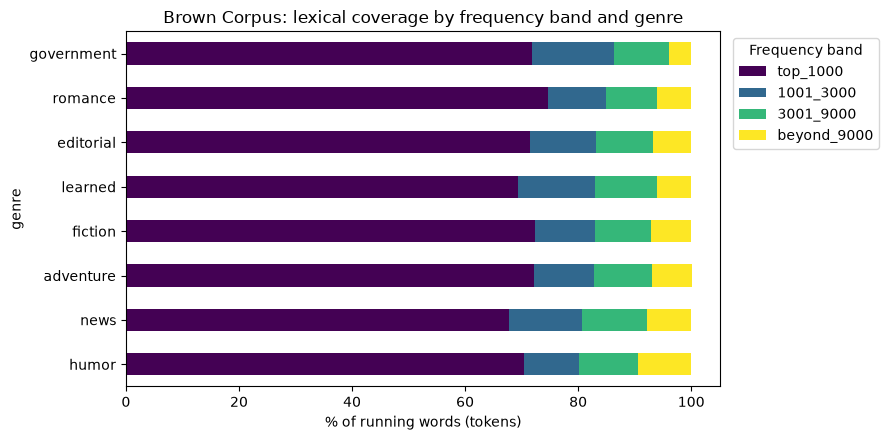

In [30]:
import matplotlib.pyplot as plt

ax = (cov_table.sort_values("cum_top_3000")
      [["top_1000", "1001_3000", "3001_9000", "beyond_9000"]]
      .plot.barh(stacked=True, figsize=(9, 4.5), colormap="viridis"))
ax.set_xlabel("% of running words (tokens)")
ax.set_title("Brown Corpus: lexical coverage by frequency band and genre")
ax.legend(title="Frequency band", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [31]:
# Teaching material: most "distinctive" mid-frequency words per genre (rank 1001-3000)
# Ranking with ROW_NUMBER inside each genre, filtering words that appear in several documents
corpus_sql('''
    WITH genre_words AS (
        SELECT d.genre, w.word, SUM(w.freq) AS freq, COUNT(DISTINCT w.doc_id) AS docs
        FROM word_counts AS w
        JOIN documents   AS d USING (doc_id)
        JOIN lexicon     AS l USING (word)
        WHERE l.freq_band = '1001_3000'
        GROUP BY d.genre, w.word
        HAVING COUNT(DISTINCT w.doc_id) >= :min_docs
    ),
    ranked AS (
        SELECT genre, word, freq, docs,
               ROW_NUMBER() OVER (PARTITION BY genre ORDER BY freq DESC, word) AS rn
        FROM genre_words
    )
    SELECT genre, GROUP_CONCAT(word, ', ') AS top_mid_frequency_words
    FROM (SELECT * FROM ranked WHERE rn <= :k ORDER BY genre, rn)
    GROUP BY genre
''', min_docs=3, k=6)

,genre,top_mid_frequency_words
0,adventure,"horses, valley, gun, rifle, wagon, bottle"
1,editorial,"budget, china, germany, editorial, tests, russia"
2,fiction,"kate, kitchen, joe, kid, sweet, watched"
3,government,"projects, vehicles, interference, payment, pro..."
4,humor,"funny, film, kitchen, newspaper, bit, dear"
5,learned,"dictionary, behavior, p, sample, poems, differ..."
6,news,"dallas, texas, mantle, jury, chairman, season"
7,romance,"baby, beautiful, pale, anne, smiled, watching"


**Leitura dos resultados (interpretação cautelosa, com base nos números acima):**
- Considerando só as **1.000 palavras mais frequentes**, *romance* tem a maior cobertura (~75% dos tokens) e *news* a menor (~68%) — textos narrativos do cotidiano reutilizam mais o vocabulário básico.
- Na cobertura acumulada **top 3.000**, *government* aparece em 1º lugar (~86%), o que à primeira vista contradiz a intuição de que textos oficiais são "difíceis". Duas explicações plausíveis (hipóteses): (1) é o gênero com **menor TTR** (~0,31), ou seja, repete muito o mesmo vocabulário técnico; (2) o `lexicon` foi construído **a partir deste mesmo subconjunto**, em que *learned* + *government* somam 110 dos 277 textos — por isso seus termos técnicos (*projects*, *payment*...) entram na faixa 1001–3000.
- *humor* e *news* concentram mais tokens além do rank 9.000 (nomes próprios como *Dallas*, *Texas*, *Mantle* e vocabulário variado).
- **Lição metodológica:** a lista de frequência de referência muda a conclusão. Para decisões pedagógicas, o ideal seria usar uma lista externa e geral (não derivada dos textos analisados), além de lematizar e tratar nomes próprios.
- Limites: o Brown é inglês americano escrito de 1961; as faixas são relativas a este corpus e não equivalem a níveis CEFR.

## 12. Boas práticas: índices, otimização e SQL vs. pandas

**Índices** funcionam como o índice remissivo de um livro: aceleram `WHERE`, `JOIN` e `ORDER BY` em colunas muito consultadas, ao custo de espaço e de escritas mais lentas.

`EXPLAIN QUERY PLAN` mostra se o SQLite fará um `SCAN` (varredura completa) ou um `SEARCH ... USING INDEX`.

In [32]:
# Index demo on the real word_counts table (hundreds of thousands of rows)
raw = corpus_engine.raw_connection()  # underlying sqlite3 connection
q = "SELECT doc_id, freq FROM word_counts WHERE word = ?"


def plan(query: str, params=()) -> str:
    '''Return SQLite's query plan as a single readable string.'''
    return " | ".join(r[-1] for r in raw.execute("EXPLAIN QUERY PLAN " + query, params))


def time_query(query: str, words: list[str], repeat: int = 3) -> float:
    '''Best-of-N time (ms) to run the query once for every word in the list.'''
    best = float("inf")
    for _ in range(repeat):
        t0 = time.perf_counter()
        for w in words:
            raw.execute(query, (w,)).fetchall()
        best = min(best, time.perf_counter() - t0)
    return best * 1000


probe_words = corpus_sql("SELECT word FROM lexicon WHERE freq_rank BETWEEN 1000 AND 1050")["word"].tolist()

print("Before index:", plan(q, ("language",)))
t_before = time_query(q, probe_words)

raw.execute("CREATE INDEX IF NOT EXISTS idx_wc_word ON word_counts(word)")
raw.commit()

print("After index: ", plan(q, ("language",)))
t_after = time_query(q, probe_words)
print(f"\n{len(probe_words)} lookups -> without index: {t_before:.1f} ms | with index: {t_after:.1f} ms "
      f"(~{t_before / max(t_after, 1e-9):.0f}x faster; timings are machine-dependent)")

Before index: SCAN word_counts


After index:  SEARCH word_counts USING INDEX idx_wc_word (word=?)

51 lookups -> without index: 383.0 ms | with index: 1.7 ms (~232x faster; timings are machine-dependent)


In [33]:
# Same question, two tools: SQL aggregation vs pandas aggregation (results must match)
t0 = time.perf_counter()
by_sql = corpus_sql('''
    SELECT d.genre, SUM(w.freq) AS tokens
    FROM word_counts w JOIN documents d USING (doc_id)
    GROUP BY d.genre ORDER BY d.genre
''')
t_sql = time.perf_counter() - t0

t0 = time.perf_counter()
by_pd = (word_counts.merge(documents[["doc_id", "genre"]], on="doc_id")
         .groupby("genre", as_index=False)["freq"].sum()
         .rename(columns={"freq": "tokens"}))
t_pd = time.perf_counter() - t0

assert (by_sql["tokens"].values == by_pd["tokens"].values).all()
print(f"Results identical ✔ | SQL: {t_sql * 1000:.1f} ms | pandas (data already in RAM): {t_pd * 1000:.1f} ms")

Results identical ✔ | SQL: 88.2 ms | pandas (data already in RAM): 36.3 ms


### Checklist de boas práticas

| Prática | Por quê |
| --- | --- |
| Use **parâmetros** (`?`, `:nome`, `text()` com *bind*) | evita *SQL injection* e erros de aspas |
| `SELECT` só as colunas necessárias (evite `SELECT *` em produção) | menos I/O e memória |
| **Filtre e agregue no banco** antes de trazer para o pandas | transfere menos dados |
| Crie **índices** nas colunas de `WHERE`/`JOIN` frequentes; confira com `EXPLAIN QUERY PLAN` | troca `SCAN` por `SEARCH` |
| Use **CTEs** para consultas longas | legibilidade e manutenção |
| Use `with engine.begin()` / `with conn:` | transações com *commit/rollback* automáticos |
| `chunksize=` para tabelas grandes | processamento em fluxo |
| Valide resultados SQL contra pandas em pontos críticos | confiança nos números |

### Quando usar SQL vs. pandas?
- **SQL**: dados grandes ou compartilhados num banco, filtros/joins/agregações pesadas, consultas reprodutíveis que outras pessoas também rodam.
- **pandas**: dados já em memória, transformações complexas linha a linha, *reshape* (`pivot`, `melt`), visualização e integração com scikit-learn.
- **Na prática, os dois juntos**: SQL para *extrair e resumir*, pandas para *explorar e modelar*.

In [34]:
# Clean up connections
raw.close()
conn.close()
engine.dispose()
corpus_engine.dispose()
print("All connections closed.")

All connections closed.


## O que aprendi hoje

1. **SQL é indispensável em DS** — aparece em grande parte das vagas e é a forma padrão de acessar dados em empresas.
2. O `sqlite3` permite criar bancos **em memória**, tabelas com restrições (`CHECK`, `NOT NULL`) e transações com `commit`/`rollback`; **placeholders** protegem contra *SQL injection*.
3. `DataFrame.to_sql()` e `pd.read_sql_query()` formam a ponte **pandas ↔ SQL** (com `params`, `dtype` e `chunksize`).
4. A ordem lógica `FROM → WHERE → GROUP BY → HAVING → SELECT → ORDER BY → LIMIT` explica `WHERE` vs. `HAVING` e `COUNT(*)` vs. `COUNT(col)`.
5. `INNER JOIN` descarta linhas sem correspondência; `LEFT JOIN` as mantém com `NULL` (vimos isso com os *decks* do Titanic).
6. **CTEs** tornam consultas legíveis como *pipelines*; **funções de janela** (`ROW_NUMBER`, `RANK`, `LAG`, `LEAD`, `SUM() OVER`) calculam rankings, variações e acumulados sem colapsar linhas — e conferem com `shift()` do pandas.
7. O **SQLAlchemy** dá portabilidade: `create_engine` + `text()`/`select()` + pandas resolvem a maioria dos casos de DS, e o ORM serve para registrar, por exemplo, resultados de experimentos.
8. Um **banco relacional de corpus** (Brown) permitiu medir **cobertura lexical por gênero** — uma ponte direta entre SQL, linguística de corpus e ensino de inglês.
9. **Índices** e `EXPLAIN QUERY PLAN` mostram, na prática, a diferença entre `SCAN` e `SEARCH`.

## Próximo passo → rumo à Fase 2 (EDA)

Com SQL no repertório, consigo **extrair e resumir dados diretamente da fonte**. Esse é exatamente o primeiro passo da **Análise Exploratória de Dados (Fase 2 — EDA)**: consultar, filtrar e agregar com SQL, e depois investigar distribuições, valores faltantes, *outliers* e relações entre variáveis com pandas e visualizações. Nos dias restantes da Fase 1 continuo consolidando os fundamentos que sustentam esse fluxo.